In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('DATASETS/new_dataset.csv', parse_dates=['date'])
df.set_index('date', inplace=True)
df.head()

,price,exchange rate (1 USD TO TZS),observation
date,,,
2010-01-01,1533.9349,1313.0056,baseline / no prior month
2010-02-01,1620.3256,1323.5843,normal month-over-month move
2010-03-01,1572.1865,1326.3845,normal month-over-month move
2010-04-01,1681.5984,1330.0796,normal month-over-month move
2010-05-01,1711.4398,1343.2834,normal month-over-month move


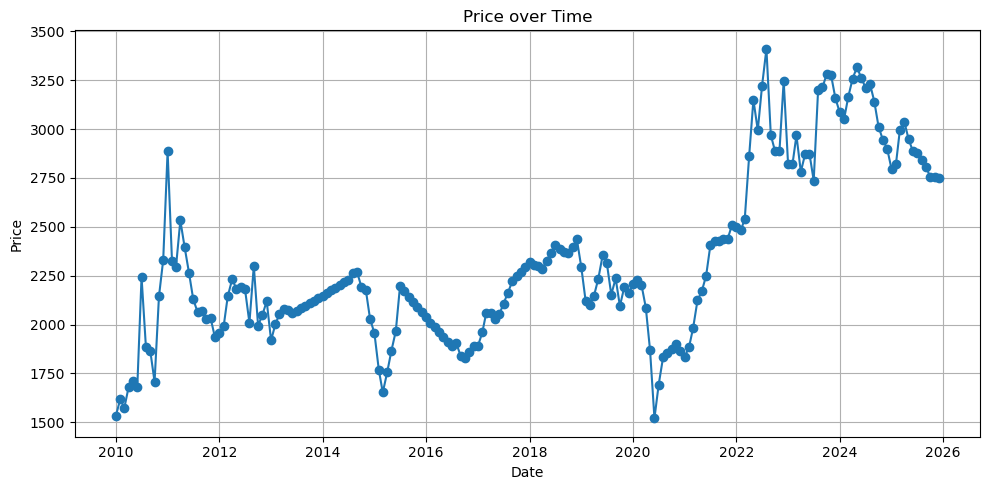

In [3]:
plt.figure(figsize=(10, 5))
plt.plot(df.index, df['price'], marker='o', linestyle='-')
plt.title('Price over Time')
plt.xlabel('Date')
plt.ylabel('Price')
plt.grid(True)
plt.tight_layout()
plt.show()

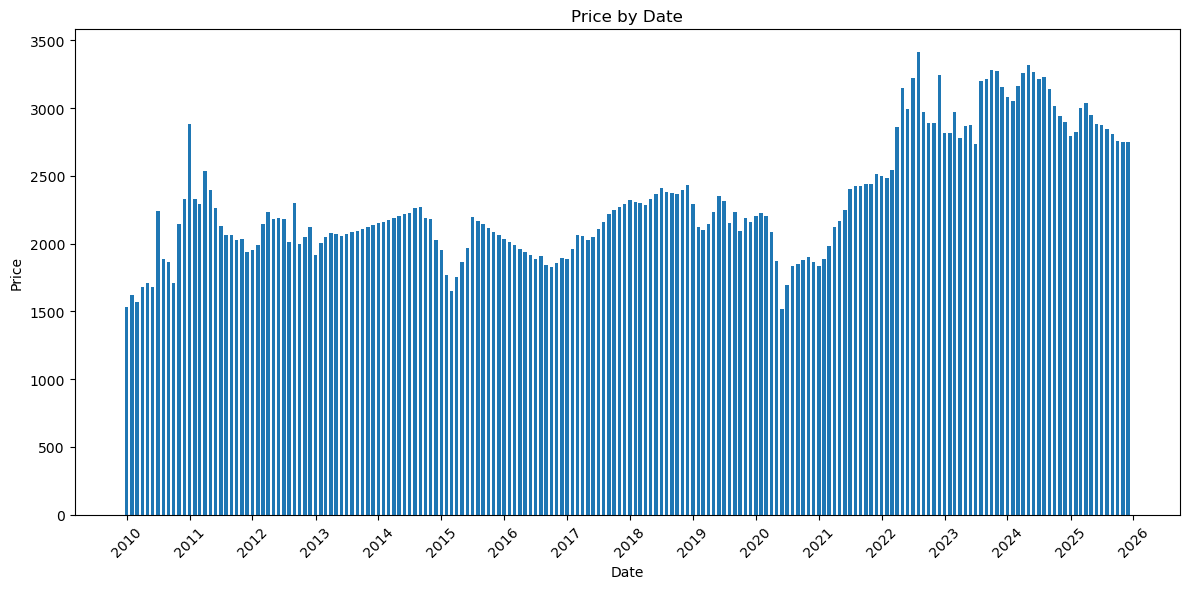

In [4]:
import matplotlib.dates as mdates

dates = mdates.date2num(df.index.to_pydatetime())

plt.figure(figsize=(12, 6))
ax = plt.gca()
ax.bar(dates, df['price'], width=20, align='center')
ax.xaxis_date()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.xlabel('Date')
plt.ylabel('Price')
plt.title('Price by Date')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

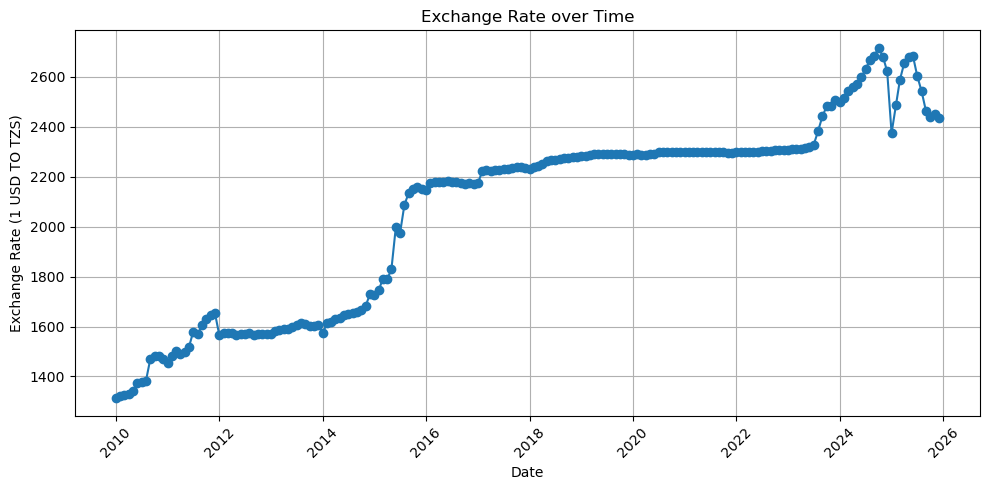

In [5]:
plt.figure(figsize=(10, 5))
plt.plot(df.index, df['exchange rate (1 USD TO TZS)'], marker='o', linestyle='-')
plt.title('Exchange Rate over Time')
plt.xlabel('Date')
plt.ylabel('Exchange Rate (1 USD TO TZS)')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

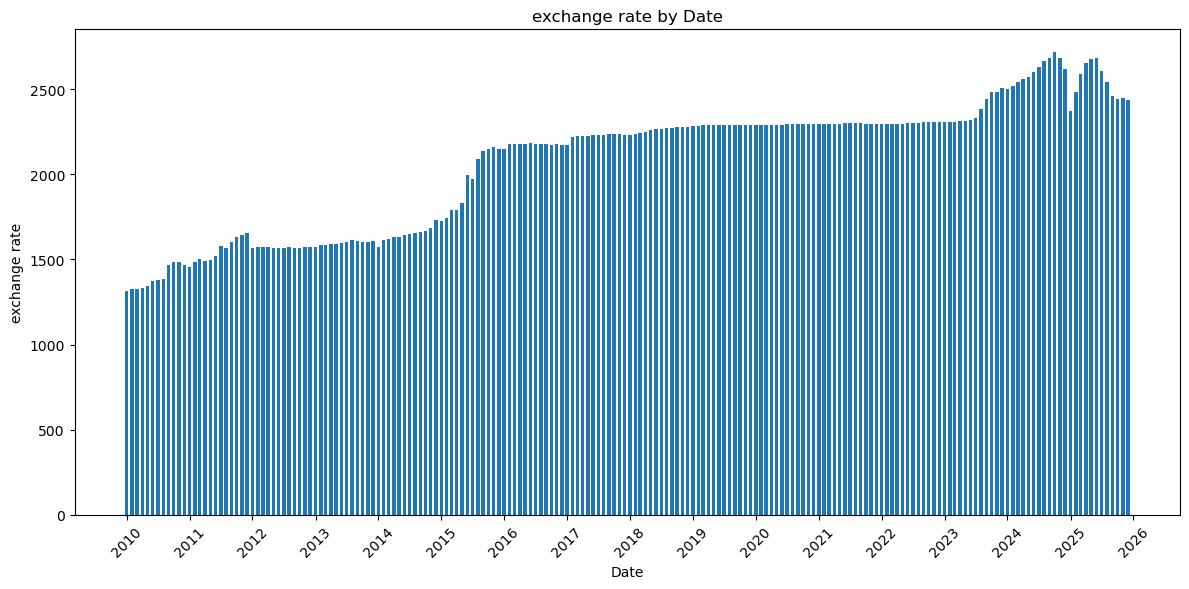

In [10]:
import matplotlib.dates as mdates

dates = mdates.date2num(df.index.to_pydatetime())

plt.figure(figsize=(12, 6))
ax = plt.gca()
ax.bar(dates, df['exchange rate (1 USD TO TZS)'], width=20, align='center')
ax.xaxis_date()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.xlabel('Date')
plt.ylabel('exchange rate')
plt.title('exchange rate by Date')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

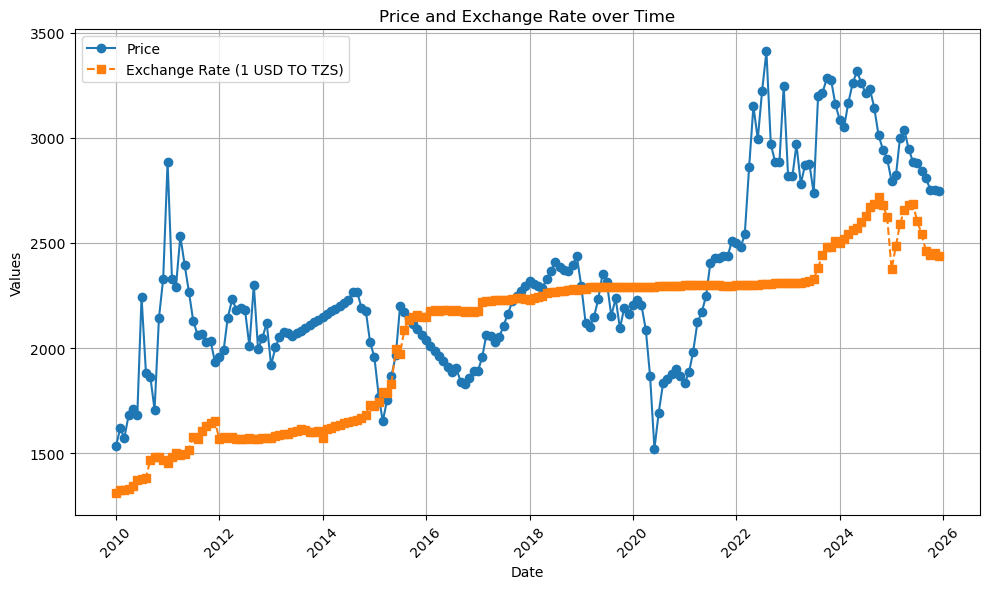

In [12]:
plt.figure(figsize=(10, 6))

# Plot Price
plt.plot(df.index, df['price'], marker='o', linestyle='-', label='Price')

# Plot Exchange Rate
plt.plot(df.index, df['exchange rate (1 USD TO TZS)'], marker='s', linestyle='--', label='Exchange Rate (1 USD TO TZS)')

# Titles and labels
plt.title('Price and Exchange Rate over Time')
plt.xlabel('Date')
plt.ylabel('Values')
plt.grid(True)
plt.xticks(rotation=45)
plt.legend()   # show legend to distinguish the two lines
plt.tight_layout()
plt.show()

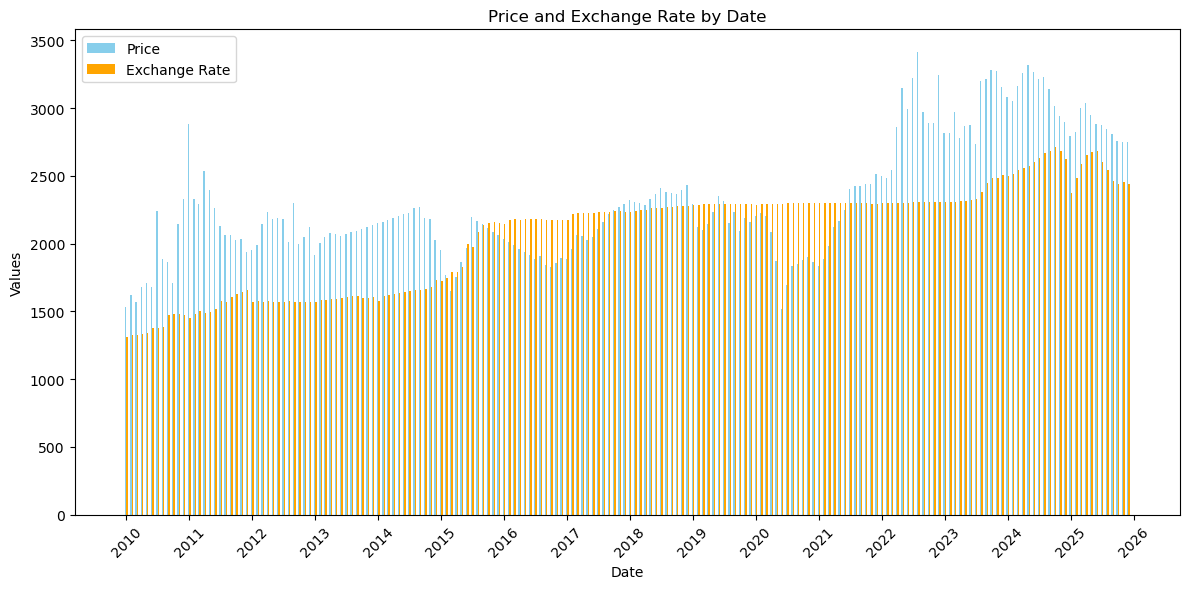

In [13]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np

# Convert dates to numeric format for matplotlib
dates = mdates.date2num(df.index.to_pydatetime())

# Bar width
width = 8  

plt.figure(figsize=(12, 6))
ax = plt.gca()

# Plot Price bars (shifted left)
ax.bar(dates - width/2, df['price'], width=width, align='center', label='Price', color='skyblue')

# Plot Exchange Rate bars (shifted right)
ax.bar(dates + width/2, df['exchange rate (1 USD TO TZS)'], width=width, align='center', label='Exchange Rate', color='orange')

# Format x-axis as dates
ax.xaxis_date()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

# Labels and title
plt.xlabel('Date')
plt.ylabel('Values')
plt.title('Price and Exchange Rate by Date')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

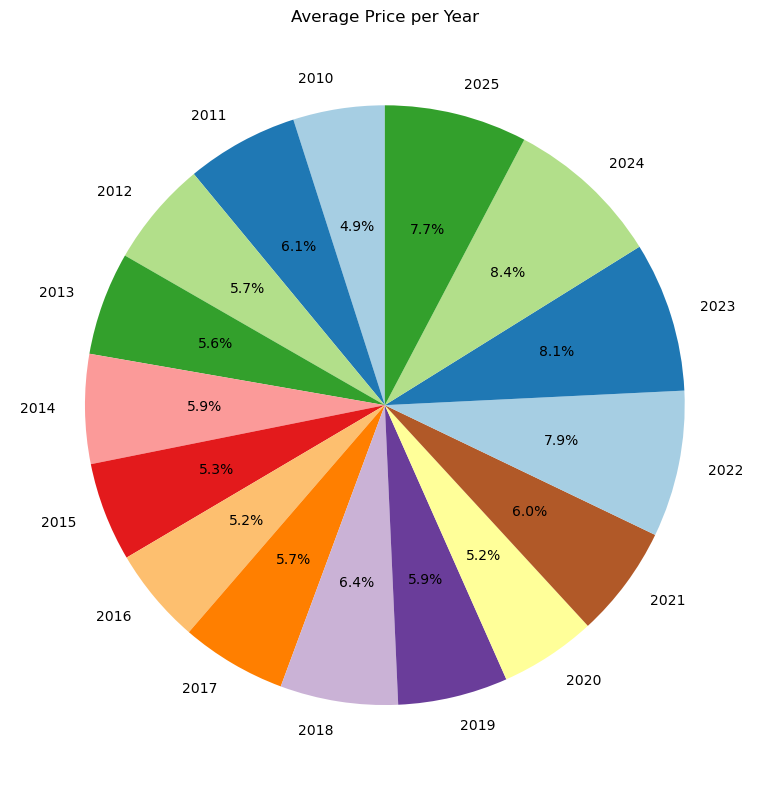

In [14]:
import matplotlib.pyplot as plt

# Step 1: Group by year and calculate average price
avg_price_per_year = df.groupby(df.index.year)['price'].mean()

# Step 2: Plot pie chart
plt.figure(figsize=(8, 8))
plt.pie(avg_price_per_year, 
        labels=avg_price_per_year.index, 
        autopct='%1.1f%%', 
        startangle=90, 
        colors=plt.cm.Paired.colors)

plt.title('Average Price per Year')
plt.tight_layout()
plt.show()

In [15]:
# Step 1: Extract year and month from the datetime index
df['Year'] = df.index.year
df['Month'] = df.index.month

# Step 2: Group by Year and Month, then calculate average (or max) price per month
monthly_avg = df.groupby(['Year', 'Month'])['price'].mean()

# Step 3: For each year, find the month with the highest price
highest_months = monthly_avg.groupby('Year').idxmax()
highest_values = monthly_avg.groupby('Year').max()

# Step 4: Combine results into a DataFrame
result = pd.DataFrame({
    'Year': [year for year, month in highest_months],
    'Month': [month for year, month in highest_months],
    'Highest Price': highest_values.values
})

print(result)

    Year  Month  Highest Price
0   2010     12      2330.4396
1   2011      1      2885.6954
2   2012      9      2300.3945
3   2013     12      2135.2834
4   2014      9      2267.7854
5   2015      7      2198.5843
6   2016      1      2036.9685
7   2017     12      2293.8342
8   2018     12      2436.1020
9   2019      6      2353.5438
10  2020      2      2226.8320
11  2021     12      2510.3720
12  2022      8      3410.6954
13  2023     10      3281.8900
14  2024      5      3315.5783
15  2025      4      3038.2344


In [18]:


# Find the maximum price
max_price = df['price'].max()

# Find the row with that maximum price
max_row = df.loc[df['price'].idxmax()]

print("Highest Price:", max_price)
print("Date:", max_row['date'])
print("Exchange Rate:", max_row['exchange rate (1 USD TO TZS)'])
print("Observation:", max_row['observation'])

Highest Price: 3410.6954


KeyError: 'date'